In [8]:
from pathlib import Path
import numpy as np
import pandas as pd

data_path = Path("dataset.npz")

with np.load(data_path, allow_pickle=False) as d:
    # Original features: scaling will happen inside each training split
    X_train = d["Xtr_raw"].copy()
    X_test = d["Xte_raw"].copy()

    y_train = d["ytr"].copy()
    y_test = d["yte"].copy()

    groups_train = d["groups_train"].copy()
    groups_test = d["groups_test"].copy()

    class_names = d["class_names"].copy()

assert np.isfinite(X_train).all()
assert np.isfinite(X_test).all()
assert set(groups_train).isdisjoint(set(groups_test))

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Training trials:", len(np.unique(groups_train)))
print("Test trials:", len(np.unique(groups_test)))
print("Classes:", class_names.tolist())

trial_counts = (
    pd.DataFrame({"trial": groups_train, "label": y_train})
    .drop_duplicates()
    .groupby("label")
    .size()
)

print("\nTraining trials per class:")
print(trial_counts)
print("\nDataset loaded successfully!")

Training features: (323, 60)
Test features: (95, 60)
Training trials: 17
Test trials: 5
Classes: ['Finger spreading', 'Fist', 'Supination', 'Pronation']

Training trials per class:
label
0    5
1    3
2    5
3    4
dtype: int64

Dataset loaded successfully!


In [2]:
import time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Each pipeline learns its scaling from training data only.
models = {
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            decision_function_shape="ovr",
            random_state=42
        )
    ),

    "Random Forest": make_pipeline(
        StandardScaler(),
        RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )
    ),

    "XGBoost": make_pipeline(
        StandardScaler(),
        XGBClassifier(
            n_estimators=400,
            max_depth=6,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.8,
            objective="multi:softprob",
            eval_metric="mlogloss",
            random_state=42,
            n_jobs=2
        )
    )
}

training_times = {}

for name, model in models.items():
    start_time = time.perf_counter()
    model.fit(X_train, y_train)
    training_times[name] = time.perf_counter() - start_time

    print(
        f"{name}: training completed "
        f"({training_times[name]:.3f} seconds)"
    )

SVM: training completed (0.021 seconds)
Random Forest: training completed (0.086 seconds)
XGBoost: training completed (0.377 seconds)


In [3]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

predictions = {}
results = []
class_labels = np.arange(len(class_names))

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred,
            labels=class_labels,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred,
            labels=class_labels,
            average="macro",
            zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred,
            labels=class_labels,
            average="macro",
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

# Display percentages, but save the original 0–1 values
display(
    results_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-score": "{:.2%}"
    })
)

results_df.to_csv("week6_holdout_results.csv", index=False)
print("Saved: week6_holdout_results.csv")

,Model,Accuracy,Precision,Recall,F1-score
0,SVM,91.58%,93.39%,90.13%,91.49%
1,Random Forest,93.68%,94.28%,94.08%,94.15%
2,XGBoost,90.53%,91.34%,92.11%,91.48%


Saved: week6_holdout_results.csv


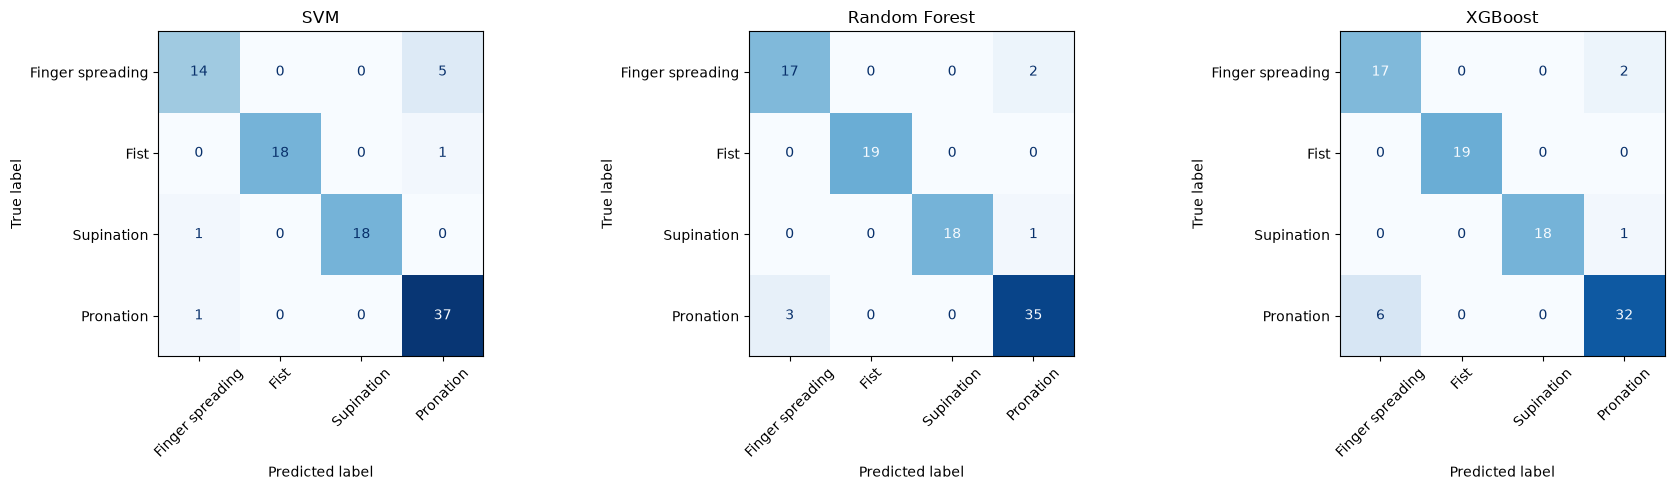

Rows = actual class; columns = predicted class
Saved: week6_confusion_matrices.png


In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
confusion_matrices = {}

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )
    confusion_matrices[name] = cm

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )
    display_cm.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False,
        xticks_rotation=45
    )

    ax.set_title(name)

    # Use the same color scale for all three models
    display_cm.im_.set_clim(0, 38)

    safe_name = name.lower().replace(" ", "_")
    pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names
    ).to_csv(f"week6_confusion_{safe_name}.csv")

plt.tight_layout()
plt.savefig("week6_confusion_matrices.png", dpi=200)
plt.show()

print("Rows = actual class; columns = predicted class")
print("Saved: week6_confusion_matrices.png")

## 혼동행렬 분석

혼동행렬의 행은 실제 클래스이고, 열은 예측 클래스이다.
테스트 데이터는 총 95개 윈도우이며, 회내는 38개,
나머지 동작은 각각 19개이다.

### SVM
95개 중 87개를 정확하게 분류하였다.
가장 많은 오류는 손가락 벌리기를 회내로 예측한 5개였다.
회내의 재현율은 37/38로 약 97.37%였지만,
손가락 벌리기의 재현율은 14/19로 약 73.68%였다.

### Random Forest
95개 중 89개를 정확하게 분류하여 이번 테스트에서
가장 높은 정확도를 보였다.
주먹 쥐기는 19개 모두 정확하게 분류하였다.
가장 많은 오류는 회내를 손가락 벌리기로 예측한 3개였다.

### XGBoost
95개 중 86개를 정확하게 분류하였다.
주먹 쥐기는 19개 모두 정확하게 분류했지만,
회내를 손가락 벌리기로 예측한 오류가 6개로 가장 많았다.

### 종합 해석
세 모델 모두 손가락 벌리기와 회내 사이에서 혼동을 보였다.
두 동작의 일부 특징이 비슷했을 가능성이 있지만,
혼동행렬만으로 오류 원인을 확정할 수는 없다.

이번 결과는 한 피험자의 테스트 시행 5개에서 나온 결과이다.
같은 시행에서 생성한 윈도우들은 서로 겹치므로,
95개 윈도우를 독립적인 95번의 실험으로 해석하면 안 된다.

In [5]:
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

# One row per training trial
trial_table = (
    pd.DataFrame({
        "trial_id": groups_train,
        "label": y_train
    })
    .drop_duplicates()
    .reset_index(drop=True)
)

assert trial_table["trial_id"].is_unique

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

fold_acc = {name: [] for name in models}
fold_details = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(trial_table["trial_id"], trial_table["label"]),
    start=1
):
    train_trial_ids = trial_table.iloc[train_idx]["trial_id"]
    val_trial_ids = trial_table.iloc[val_idx]["trial_id"]

    # Select every window belonging to each trial
    train_mask = np.isin(groups_train, train_trial_ids)
    val_mask = np.isin(groups_train, val_trial_ids)

    assert set(train_trial_ids).isdisjoint(set(val_trial_ids))
    assert set(y_train[train_mask]) == set(class_labels)
    assert set(y_train[val_mask]) == set(class_labels)

    fold_details.append({
        "Fold": fold,
        "Train trials": len(train_trial_ids),
        "Validation trials": len(val_trial_ids),
        "Train windows": int(train_mask.sum()),
        "Validation windows": int(val_mask.sum())
    })

    for name, prototype in models.items():
        # Clone creates an unfitted pipeline.
        # Scaling is learned only from this fold's training data.
        model = clone(prototype)
        model.fit(X_train[train_mask], y_train[train_mask])

        pred = model.predict(X_train[val_mask])
        acc = accuracy_score(y_train[val_mask], pred)
        fold_acc[name].append(acc)

        print(f"Fold {fold} | {name}: {acc:.2%}")

fold_results = pd.DataFrame(
    fold_acc,
    index=pd.Index([1, 2, 3], name="Fold")
)

cv_summary = pd.DataFrame([
    {
        "Model": name,
        "Mean accuracy (%)": np.mean(scores) * 100,
        "Std (%)": np.std(scores, ddof=0) * 100
    }
    for name, scores in fold_acc.items()
])

display(pd.DataFrame(fold_details))
display((fold_results * 100).round(2))
display(cv_summary.round(2))

fold_results.to_csv("week6_cv_fold_accuracy.csv")
cv_summary.to_csv("week6_cv_summary.csv", index=False)

Fold 1 | SVM: 98.25%
Fold 1 | Random Forest: 96.49%
Fold 1 | XGBoost: 93.86%
Fold 2 | SVM: 94.74%
Fold 2 | Random Forest: 85.09%
Fold 2 | XGBoost: 87.72%
Fold 3 | SVM: 93.68%
Fold 3 | Random Forest: 90.53%
Fold 3 | XGBoost: 92.63%


,Fold,Train trials,Validation trials,Train windows,Validation windows
0,1,11,6,209,114
1,2,11,6,209,114
2,3,12,5,228,95


,SVM,Random Forest,XGBoost
Fold,,,
1,98.25,96.49,93.86
2,94.74,85.09,87.72
3,93.68,90.53,92.63


,Model,Mean accuracy (%),Std (%)
0,SVM,95.56,1.95
1,Random Forest,90.70,4.66
2,XGBoost,91.40,2.65


In [6]:
from scipy.stats import ttest_rel
from itertools import combinations

test_rows = []

for model_a, model_b in combinations(fold_acc.keys(), 2):
    scores_a = np.asarray(fold_acc[model_a])
    scores_b = np.asarray(fold_acc[model_b])
    differences = scores_a - scores_b

    if np.isclose(np.std(differences), 0):
        t_stat, p_value = np.nan, np.nan
        interpretation = "Cannot reliably calculate: constant differences"
    else:
        t_stat, p_value = ttest_rel(scores_a, scores_b)
        interpretation = (
            "Difference detected (uncorrected p < 0.05)"
            if p_value < 0.05
            else "No significant difference detected"
        )

    test_rows.append({
        "Comparison": f"{model_a} vs {model_b}",
        "Mean difference (percentage points)": differences.mean() * 100,
        "t-statistic": t_stat,
        "p-value": p_value,
        "Interpretation": interpretation
    })

ttest_results = pd.DataFrame(test_rows)

display(ttest_results.round(4))
ttest_results.to_csv("week6_paired_ttests.csv", index=False)

print("Exploratory paired tests using 3 matching folds.")
print("P-values are uncorrected for the 3 comparisons.")
print("A non-significant result does not prove equal performance.")

,Comparison,Mean difference (percentage points),t-statistic,p-value,Interpretation
0,SVM vs Random Forest,4.8538,1.9961,0.1840,No significant difference detected
1,SVM vs XGBoost,4.1520,2.4057,0.1379,No significant difference detected
2,Random Forest vs XGBoost,-0.7018,-0.4193,0.7157,No significant difference detected


Exploratory paired tests using 3 matching folds.
P-values are uncorrected for the 3 comparisons.
A non-significant result does not prove equal performance.


In [7]:
import platform
import sys
import sklearn
import xgboost

timing_rows = []
N_REPEATS = 100

for name, fitted_model in models.items():
    # Warm up before measuring
    for _ in range(10):
        fitted_model.predict(X_test[:1])

    # Measure individual predictions across test windows
    durations_ms = []

    for i in range(N_REPEATS):
        idx = i % len(X_test)
        sample = X_test[idx:idx + 1]

        start = time.perf_counter()
        fitted_model.predict(sample)
        durations_ms.append(
            (time.perf_counter() - start) * 1000
        )

    timing_rows.append({
        "Model": name,
        "Training time (s)": training_times[name],
        "Mean inference (ms/window)": np.mean(durations_ms),
        "Median inference (ms/window)": np.median(durations_ms)
    })

timing_df = pd.DataFrame(timing_rows)
display(timing_df.round(4))

timing_df.to_csv("week6_computation_cost.csv", index=False)

print("OS:", platform.platform())
print("Architecture:", platform.machine())
print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("Timed predictions per model:", N_REPEATS)

,Model,Training time (s),Mean inference (ms/window),Median inference (ms/window)
0,SVM,0.0214,0.3142,0.2527
1,Random Forest,0.0857,14.0558,13.9535
2,XGBoost,0.3769,0.2915,0.2559


OS: macOS-26.5.1-arm64-arm-64bit
Architecture: arm64
Python: 3.12.4
scikit-learn: 1.9.0
XGBoost: 3.4.1
Timed predictions per model: 100


## 교차검증 및 통계 검정

학습 데이터에서 시행 단위 3-fold 교차검증을 수행하였다.
주먹 쥐기의 학습 시행이 3개이므로 각 검증 폴드에 모든 클래스를
포함하기 위해 강의의 5-fold를 3-fold로 변경하였다.
같은 시행의 윈도우는 함께 배치하고, 각 학습 폴드에서만
표준화 통계를 계산하였다.

| 모델 | 평균 정확도 (%) | 폴드 간 표준편차 |
|---|---:|---:|
| SVM | 95.56 | 1.95 |
| Random Forest | 90.70 | 4.66 |
| XGBoost | 91.40 | 2.65 |

SVM의 평균 정확도가 가장 높았고, 폴드 간 변동도 가장 작았다.
반면 hold-out 테스트에서는 Random Forest가 가장 높아
데이터 분할에 따라 모델 순위가 달라질 수 있음을 확인하였다.

같은 폴드의 정확도를 짝지어 대응표본 t-검정을 수행하였다.

| 비교 | p-value |
|---|---:|
| SVM vs Random Forest | 0.1840 |
| SVM vs XGBoost | 0.1379 |
| Random Forest vs XGBoost | 0.7157 |

세 비교 모두 p-value가 0.05보다 커서 유의한 차이를 검출하지 못하였다.
이는 모델의 성능이 같다는 뜻은 아니다.
폴드가 3개뿐이고 학습 데이터가 폴드 사이에서 겹치므로,
검정 결과는 탐색적으로 해석하였다.
세 비교에 대한 다중비교 보정은 적용하지 않았다.

## 계산 비용

| 모델 | 학습 시간 (초) | 평균 추론 시간 (ms/윈도우) | 중앙값 (ms/윈도우) |
|---|---:|---:|---:|
| SVM | 0.0214 | 0.3142 | 0.2527 |
| Random Forest | 0.0857 | 14.0558 | 13.9535 |
| XGBoost | 0.3769 | 0.2915 | 0.2559 |

측정 환경은 macOS 26.5.1, ARM64, Python 3.12.4,
scikit-learn 1.9.0, XGBoost 3.4.1이다.

학습 시간은 표준화와 모델 학습을 포함한 1회 측정값이다.
추론 시간은 준비 실행 10회 후 단일 윈도우 예측을
100회 반복하여 측정하였다.
추론에는 표준화가 포함되지만 필터링과 특징 추출은 포함되지 않는다.

SVM의 학습 시간이 가장 짧았고 XGBoost의 학습 시간이 가장 길었다.
평균 추론 시간은 XGBoost가 가장 짧았지만 SVM과 중앙값은 비슷하였다.
Random Forest의 단일 윈도우 예측은 상대적으로 느렸다.
이 결과는 현재 장치와 실행 설정에서의 측정값이며,
다른 환경이나 배치 예측에서도 같은 순서라고 단정할 수 없다.

## 실험의 한계

1. 한 피험자의 데이터만 사용하였다.
   시행 단위 분할은 새로운 사람에 대한 성능을 평가하지 못한다.

2. 테스트 시행이 5개이고 교차검증도 3개 폴드뿐이므로
   결과가 분할에 영향을 받을 수 있다.
   서로 겹치는 윈도우를 독립적인 실험으로 볼 수 없다.

3. 2초보다 짧은 주먹 쥐기 시행 2개를 제외하여
   클래스별 데이터 수가 다르다.

4. 원 논문의 8클래스·5채널 대신 4클래스·12채널을 사용하였다.
   따라서 논문의 성능 수치와 직접적인 우열 비교는 어렵다.

5. ZC 임계값을 0으로 설정하여 작은 잡음에도 민감할 수 있다.
   임계값과 모델 설정의 최적화는 수행하지 않았다.

## 최종 결과 및 느낀 점

동일한 데이터와 분할을 사용하여 SVM, Random Forest,
XGBoost를 비교하였다.
Hold-out에서는 Random Forest가 가장 높은 정확도와 macro F1을
보였고, 교차검증에서는 SVM의 평균 정확도가 가장 높았다.

이번 실험에서는 SVM이 교차검증 정확도와 학습 시간 측면에서
좋은 결과를 보였지만, 통계적으로 우수하다고 결론 내릴 근거는 부족하다.
모델을 평가할 때 정확도 하나만 보기보다 오류 유형,
분할에 따른 변동과 계산 비용을 함께 확인해야 한다는 것을 배웠다.

## GitHub Repository

https://github.com/BK2JJ/semg-auth